In [1]:
# Verificação de versões
import pandas as pd
import sklearn
import matplotlib
import seaborn as sns
import joblib

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Joblib:", joblib.__version__)

Pandas: 3.1.1
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
Seaborn: 0.13.2
Joblib: 1.6.0


In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# 1. Carregando o dataset
iris = load_iris()

# X são as características (features) e y é o alvo (target)
X = iris.data
y = iris.target

# 2. Dividindo os dados em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Dados carregados com sucesso!")
print(f"Total de amostras de treino: {len(X_train)}")
print(f"Total de amostras de teste: {len(X_test)}")

Dados carregados com sucesso!
Total de amostras de treino: 120
Total de amostras de teste: 30


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Criando o pipeline: Passo 1 é a normalização, Passo 2 é o classificador
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=42))
])

# Treinando o modelo com os dados de treino
pipeline.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


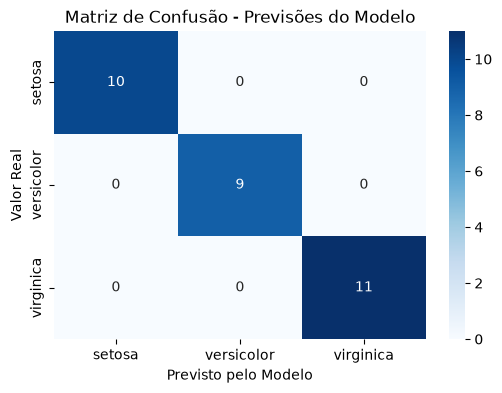

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Executando o modelo nos dados de teste
y_pred = pipeline.predict(X_test)

# 2. Criando a visualização da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=iris.target_names, 
            yticklabels=iris.target_names)
plt.title('Matriz de Confusão - Previsões do Modelo')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Valor Real')
plt.show()

In [5]:
# 1. Criando um DataFrame do Pandas com os resultados
resultados = pd.DataFrame(X_test, columns=iris.feature_names)
resultados['Target_Real'] = y_test
resultados['Target_Previsto'] = y_pred

# 2. Convertendo os números para os nomes das flores para ficar mais legível (opcional)
resultados['Flor_Real'] = resultados['Target_Real'].apply(lambda x: iris.target_names[x])
resultados['Flor_Prevista'] = resultados['Target_Previsto'].apply(lambda x: iris.target_names[x])

# 3. Salvando em CSV
nome_arquivo = 'resultados_modelo.csv'
resultados.to_csv(nome_arquivo, index=False)

print(f"Resultados salvos com sucesso no arquivo: {nome_arquivo}")

Resultados salvos com sucesso no arquivo: resultados_modelo.csv


In [6]:
import joblib

# Salvando o pipeline completo (normalização + modelo treinado) em um arquivo
nome_modelo = 'modelo_iris_observatorio.pkl'
joblib.dump(pipeline, nome_modelo)

print(f"Modelo salvo com sucesso no arquivo: {nome_modelo}")

Modelo salvo com sucesso no arquivo: modelo_iris_observatorio.pkl


In [7]:
# 1. Carregando o modelo que acabamos de salvar do disco
modelo_carregado = joblib.load('modelo_iris_observatorio.pkl')

# 2. Pegando uma amostra (a primeira flor do conjunto de teste)
amostra = X_test[0].reshape(1, -1) 

# 3. Fazendo a previsão com o modelo carregado
previsao = modelo_carregado.predict(amostra)

print("Modelo carregado com sucesso!")
print(f"Características da flor: {amostra}")
print(f"Previsão do modelo: {iris.target_names[previsao[0]]} (Classe {previsao[0]})")

Modelo carregado com sucesso!
Características da flor: [[6.1 2.8 4.7 1.2]]
Previsão do modelo: versicolor (Classe 1)
